# Sensor classification

Classify the screened corpus using literal sensor terms and semantic similarity.

## Libraries

In [1]:
import json
import os
import re
from collections import Counter

import numpy as np
import pandas as pd
from tqdm import tqdm

import torch
from sentence_transformers import SentenceTransformer, util
from sklearn.metrics import roc_curve

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_colwidth", 100)
sns.set(style="whitegrid")
plt.rcParams.update({"font.size": 12})
plt.rcParams.update({"font.family": "Times New Roman"})


## Load data

Use title, contribution, abstract, and author keywords for term matching. Score the contribution, falling back to the introduction.

In [2]:
df = pd.read_json("../data/06_1_classified_walkability_dimensions.json")

def get_scoring_text(row):
    contribution = row.get("contribution")
    if isinstance(contribution, str) and contribution.strip():
        return contribution.strip()
    introduction = row.get("introduction")
    if isinstance(introduction, str) and introduction.strip():
        return introduction.strip()
    return None


def get_gate_text(row):
    """Combine title, contribution, abstract, and author keywords for term matching."""
    parts = [row.get("title"), row.get("contribution"), row.get("abstract")]
    author_keywords = row.get("author_keywords")
    if isinstance(author_keywords, list):
        parts.append(" ".join(k for k in author_keywords if isinstance(k, str)))
    elif isinstance(author_keywords, str):
        parts.append(author_keywords)
    joined = " ".join(p.strip() for p in parts if isinstance(p, str) and p.strip())
    return joined if joined else None


df["scoring_text"] = df.apply(get_scoring_text, axis=1)
df["gate_text"] = df.apply(get_gate_text, axis=1)

n_used_contribution = df["contribution"].apply(lambda t: isinstance(t, str) and bool(t.strip())).sum()
falling_back_to_introduction = int(df["scoring_text"].notna().sum()) - int(n_used_contribution)
print(f"Total articles processed: {len(df)}")
print(f"Articles using 'contribution' as the scoring text: {n_used_contribution}")
print(f"Articles falling back to 'introduction': {falling_back_to_introduction}")

gate_len = df["gate_text"].fillna("").str.len()
scoring_len = df["scoring_text"].fillna("").str.len()
print(f"Median gate_text length: {gate_len.median():.0f} chars "
      f"(vs {scoring_len.median():.0f} for scoring_text)")


Total articles processed: 474
Articles using 'contribution' as the scoring text: 474
Articles falling back to 'introduction': 0
Median gate_text length: 2874 chars (vs 1184 for scoring_text)


## Sensor taxonomy

Load category keywords from `sensor_technology_domains.json` and root terms from `sensor_gate_terms.json`.

In [3]:
with open("../data/config/sensor_technology_domains.json", "r", encoding="utf8") as f:
    sensor_technologies = json.load(f)

with open("../data/config/sensor_gate_terms.json", "r", encoding="utf8") as f:
    gate_terms_raw = json.load(f)
gate_extra_terms = {k: v for k, v in gate_terms_raw.items() if not k.startswith("_")}

assert set(gate_extra_terms) == set(sensor_technologies), (
    "Gate config and taxonomy must cover exactly the same macro categories.\n"
    f"  only in taxonomy: {set(sensor_technologies) - set(gate_extra_terms)}\n"
    f"  only in gate:     {set(gate_extra_terms) - set(sensor_technologies)}"
)

keyword_to_macro = {}
for macro_category, keywords in sensor_technologies.items():
    for keyword in keywords:
        keyword_to_macro[keyword] = macro_category

keyword_list = list(keyword_to_macro.keys())


def _term_to_pattern(term):
    parts = [re.escape(tok) for tok in re.split(r"[\s\-]+", term.strip().lower()) if tok]
    if not parts:
        return None
    body = r"[\s\-]*".join(parts)
    left = r"\b" if term[:1].isalnum() else ""
    right = r"(?:s|es)?\b" if term[-1:].isalnum() else ""
    return f"{left}{body}{right}"


gate_patterns = {}
gate_term_index = {}
for macro_category in sensor_technologies:
    terms = list(sensor_technologies[macro_category]) + list(gate_extra_terms[macro_category])
    patterns = [p for p in (_term_to_pattern(t) for t in terms) if p]
    gate_patterns[macro_category] = re.compile("|".join(patterns), re.IGNORECASE)
    gate_term_index[macro_category] = terms

print(f"Total number of keyword phrases (semantic scoring): {len(keyword_list)}")
print(f"Macro sensor categories: {list(sensor_technologies.keys())}")
print("\nGate terms per category (taxonomy keywords + root forms):")
for macro_category in sensor_technologies:
    print(f"  - {macro_category}: {len(sensor_technologies[macro_category])} + "
          f"{len(gate_extra_terms[macro_category])} = {len(gate_term_index[macro_category])}")


Total number of keyword phrases (semantic scoring): 119
Macro sensor categories: ['Optical Imaging', 'Active Ranging and 3D Scanning', 'Acoustic Sensing', 'Inertial Motion Sensing', 'Positioning and Localization', 'Atmospheric and Environmental Sensing', 'Physiological Sensing']

Gate terms per category (taxonomy keywords + root forms):
  - Optical Imaging: 30 + 8 = 38
  - Active Ranging and 3D Scanning: 16 + 9 = 25
  - Acoustic Sensing: 12 + 6 = 18
  - Inertial Motion Sensing: 11 + 4 = 15
  - Positioning and Localization: 13 + 6 = 19
  - Atmospheric and Environmental Sensing: 23 + 17 = 40
  - Physiological Sensing: 14 + 7 = 21


## Semantic model

In [4]:
DEVICE = (
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)
print(f"Using device: {DEVICE}")

HF_CACHE_DIR = r"C:\Users\vinic\.cache\huggingface\hub"
MODEL_ID = "sentence-transformers/all-mpnet-base-v2"
CACHE_PATH = os.path.join(HF_CACHE_DIR, "models--sentence-transformers--all-mpnet-base-v2")

if not os.path.exists(CACHE_PATH):
    raise FileNotFoundError(
        f"SentenceTransformer model cache not found at: {CACHE_PATH}\n"
        "Either download it once on a networked machine or point cache_folder to a valid local HF cache."
    )

os.environ.setdefault("HF_HUB_OFFLINE", "1")

sbert_model = SentenceTransformer(
    MODEL_ID,
    device=DEVICE,
    cache_folder=HF_CACHE_DIR,
    local_files_only=True,
)
keyword_embeddings = sbert_model.encode(keyword_list, convert_to_tensor=True)


Using device: cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

## Sensor detection

Score only categories with a literal term match. Use the highest keyword similarity across text segments; unmatched categories retain a score of zero.

In [5]:
def gate_macro_categories(text):
    """Return categories with a literal sensor-term match."""
    if not isinstance(text, str) or not text.strip():
        return []
    return [cat for cat, pattern in gate_patterns.items() if pattern.search(text)]


def gate_matched_terms(text, macro_category, limit=6):
    """Return matched gate terms for a category."""
    if not isinstance(text, str) or not text.strip():
        return []
    hits = []
    for term in gate_term_index[macro_category]:
        pattern = _term_to_pattern(term)
        if pattern and re.search(pattern, text, re.IGNORECASE):
            hits.append(term)
            if len(hits) >= limit:
                break
    return hits


def detect_sensor_technologies(text, gate_text=None, top_k_per_segment=5):
    """Gate on literal terms, then score eligible categories by maximum keyword similarity."""
    empty_result = {
        "matched_keywords": [],
        "keyword_scores": {},
        "macro_scores": {cat: 0.0 for cat in sensor_technologies},
        "gated_categories": [],
        "gate_hits": {},
    }
    if text is None or not isinstance(text, str) or text.strip() == "":
        return empty_result

    gate_source = gate_text if isinstance(gate_text, str) and gate_text.strip() else text
    gated = gate_macro_categories(gate_source)
    if not gated:
        return empty_result

    candidate_idxs = [i for i, kw in enumerate(keyword_list) if keyword_to_macro[kw] in gated]
    candidate_keywords = [keyword_list[i] for i in candidate_idxs]

    sentences = re.split(r"[.!?]", text)
    sentences = [s.strip() for s in sentences if len(s.strip()) > 20]
    text_segments = sentences if len(sentences) > 3 else [text]

    try:
        segment_embeddings = sbert_model.encode(text_segments, convert_to_tensor=True)
        candidate_embeddings = keyword_embeddings[candidate_idxs]
        similarities = util.pytorch_cos_sim(segment_embeddings, candidate_embeddings)
        max_sim_per_keyword = similarities.max(dim=0).values
        keyword_scores = {
            candidate_keywords[i]: max_sim_per_keyword[i].item()
            for i in range(len(candidate_keywords))
        }
    except Exception as e:
        print(f"Error in semantic matching: {e}")
        return empty_result

    matched_keywords = sorted(keyword_scores.items(), key=lambda x: x[1], reverse=True)[:top_k_per_segment]
    macro_scores = {cat: 0.0 for cat in sensor_technologies}
    for keyword, score in keyword_scores.items():
        macro_category = keyword_to_macro[keyword]
        macro_scores[macro_category] = max(macro_scores[macro_category], score)

    return {
        "matched_keywords": matched_keywords,
        "keyword_scores": keyword_scores,
        "macro_scores": macro_scores,
        "gated_categories": gated,
        "gate_hits": {cat: gate_matched_terms(gate_source, cat) for cat in gated},
    }


## Classify the corpus

In [6]:
df_filtered = df[df["scoring_text"].notna()].copy()
print(f"Classifying {len(df_filtered)} abstracts...")

tqdm.pandas(desc="Detecting sensor technologies")
detection_results = df_filtered.progress_apply(
    lambda row: detect_sensor_technologies(row["scoring_text"], gate_text=row["gate_text"]),
    axis=1,
)

df_filtered["sensor_matched_keywords"] = detection_results.apply(lambda r: r["matched_keywords"])
df_filtered["sensor_macro_scores"] = detection_results.apply(lambda r: r["macro_scores"])
df_filtered["sensor_gated_categories"] = detection_results.apply(lambda r: r["gated_categories"])
df_filtered["sensor_gate_hits"] = detection_results.apply(lambda r: r["gate_hits"])

n_no_gate = int((df_filtered["sensor_gated_categories"].apply(len) == 0).sum())
avg_gated = float(df_filtered["sensor_gated_categories"].apply(len).mean())
n_categories = len(sensor_technologies)

gate_on_scoring_only = df_filtered["scoring_text"].apply(
    lambda t: len(gate_macro_categories(t)) > 0
).sum()
gate_on_full = int((df_filtered["sensor_gated_categories"].apply(len) > 0).sum())
print(f"\nRecords gated using scoring text: {gate_on_scoring_only}")
print(f"Records gated using combined text: {gate_on_full}")
print(f"Recovered by the wider gate text: {gate_on_full - gate_on_scoring_only}")

print(f"\nRecords with no category passing the gate: {n_no_gate} "
      f"({n_no_gate / len(df_filtered) * 100:.1f}%)")
print(f"Mean gated categories per record: {avg_gated:.2f} of {n_categories}")
print(f"Semantic comparisons avoided by gating: "
      f"~{(1 - avg_gated / n_categories) * 100:.0f}%")

gate_freq = Counter()
for cats in df_filtered["sensor_gated_categories"]:
    gate_freq.update(cats)
print("\nGate firing frequency by category:")
for category in sensor_technologies:
    n = gate_freq.get(category, 0)
    print(f"  - {category}: {n} ({n / len(df_filtered) * 100:.1f}%)")

print("\nMost frequent gate terms per category:")
for category in sensor_technologies:
    term_freq = Counter()
    for hits in df_filtered["sensor_gate_hits"]:
        term_freq.update(hits.get(category, []))
    top = ", ".join(f"{t} ({n})" for t, n in term_freq.most_common(5))
    print(f"  - {category}: {top if top else '(none)'}")


Classifying 474 abstracts...


Detecting sensor technologies: 100%|██████████| 474/474 [00:46<00:00, 10.18it/s]



Records gated using scoring text: 329
Records gated using combined text: 383
Recovered by the wider gate text: 54

Records with no category passing the gate: 91 (19.2%)
Mean gated categories per record: 0.94 of 7
Semantic comparisons avoided by gating: ~87%

Gate firing frequency by category:
  - Optical Imaging: 273 (57.6%)
  - Active Ranging and 3D Scanning: 51 (10.8%)
  - Acoustic Sensing: 3 (0.6%)
  - Inertial Motion Sensing: 35 (7.4%)
  - Positioning and Localization: 48 (10.1%)
  - Atmospheric and Environmental Sensing: 20 (4.2%)
  - Physiological Sensing: 16 (3.4%)

Most frequent gate terms per category:
  - Optical Imaging: street view (208), imagery (77), google street view (67), street view imagery (53), camera (41)
  - Active Ranging and 3D Scanning: lidar (48), 3d (27), point cloud (16), light detection and ranging (9), laser scanning (4)
  - Acoustic Sensing: audio recording (2), microphone (1), sound level meter (1), sound pressure level (1), sound level (1)
  - Inertial

## Threshold calibration

Calibrate for 95% recall among gated records in `real.json`. Report overall recall including gate misses. Calibration uses the available text; author-keyword coverage may differ from the corpus.

In [7]:
real_df = pd.read_json("../model/dataset/real.json")

REAL_TEXT_FIELD_CANDIDATES = ["contribution", "introduction", "abstract", "text", "contribution_text"]
REAL_LABEL_FIELD_CANDIDATES = ["label", "is_walkability_related", "walkability", "y", "class"]
POSITIVE_LABEL_VALUES = {1, "1", True, "true", "True", "positive", "Positive", "yes", "Yes",
                          "Sensing of walkability dimension", "sensing of walkability dimension"}

def get_text(record, field_candidates=REAL_TEXT_FIELD_CANDIDATES):
    for field in field_candidates:
        val = record.get(field)
        if isinstance(val, str) and val.strip():
            return val.strip()
    return None

def get_label(record, field_candidates=REAL_LABEL_FIELD_CANDIDATES, positive_values=POSITIVE_LABEL_VALUES):
    for field in field_candidates:
        if field in record and record[field] is not None:
            return 1 if record[field] in positive_values else 0
    return None

real_df["text"] = real_df.apply(lambda r: get_text(r.to_dict()), axis=1)
real_df["label"] = real_df.apply(lambda r: get_label(r.to_dict()), axis=1)
real_df = real_df.dropna(subset=["text", "label"]).reset_index(drop=True)
real_df["label"] = real_df["label"].astype(int)

tqdm.pandas(desc="Detecting sensor technologies in real.json")
real_detection = real_df["text"].progress_apply(
    lambda t: detect_sensor_technologies(t, gate_text=t)
)
real_df["macro_scores"] = real_detection.apply(lambda r: r["macro_scores"])
real_df["gated_categories"] = real_detection.apply(lambda r: r["gated_categories"])
real_df["best_sensor_score"] = real_df["macro_scores"].apply(lambda s: max(s.values()))

print(f"Loaded {len(real_df)} labeled records from real.json "
      f"({real_df['label'].sum()} positive / confirmed sensor-based walkability-dimension articles)")

pos = real_df[real_df["label"] == 1]
lost_by_gate = int((pos["gated_categories"].apply(len) == 0).sum())
print(f"\nConfirmed positives without a gate match: "
      f"{lost_by_gate}/{len(pos)} ({lost_by_gate / max(len(pos), 1) * 100:.1f}%)")
if lost_by_gate:
    print("Confirmed positives without a gate match:")
    for t in pos.loc[pos["gated_categories"].apply(len) == 0, "text"].head(10):
        print(f"  - {t[:110]}")


Detecting sensor technologies in real.json: 100%|██████████| 100/100 [00:12<00:00,  8.25it/s]

Loaded 100 labeled records from real.json (45 positive / confirmed sensor-based walkability-dimension articles)

Confirmed positives without a gate match: 4/45 (8.9%)
Confirmed positives without a gate match:
  - ALF–Score—A novel approach to build a predictive network–based walkability scoring system. Walkability is a te
  - Wearable Sensor-based Walkability Assessment at Ferry Terminal Using Machine Learning: A Case Study of Mokpo, 
  - Walkability under Climate Pressure: Application to Three UNESCO World Heritage Cities in Central Spain. Walkab
  - CrowdWatch: Dynamic Sidewalk Obstacle Detection Using Mobile Crowd Sensing. Pedestrians distracted by smartpho


In [8]:
def threshold_for_target_recall(y_true, scores, target_recall):
    """Return the highest ROC threshold meeting the target recall."""
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    valid = tpr >= target_recall
    if not valid.any():
        best_idx = int(np.argmax(tpr))
        return float(thresholds[best_idx]), float(tpr[best_idx])
    candidate_idxs = np.where(valid)[0]
    best_idx = candidate_idxs[np.argmax(thresholds[candidate_idxs])]
    return float(thresholds[best_idx]), float(tpr[best_idx])


TARGET_SENSOR_RECALL = 0.95

gated_mask = real_df["gated_categories"].apply(len) > 0
n_excluded = int((~gated_mask).sum())
n_excluded_pos = int((~gated_mask & (real_df["label"] == 1)).sum())

calib_df = real_df[gated_mask]
print(f"Calibrating on {len(calib_df)} of {len(real_df)} real.json records "
      f"({n_excluded} excluded as gate misses, of which {n_excluded_pos} were positives)")

CALIBRATED_THRESHOLD, achieved_recall = threshold_for_target_recall(
    calib_df["label"], calib_df["best_sensor_score"], TARGET_SENSOR_RECALL
)

if CALIBRATED_THRESHOLD <= 0:
    raise ValueError(
        f"Calibrated threshold is {CALIBRATED_THRESHOLD:.4f}, which is at or below the "
        "score floor. Any category scoring 0.0 would clear it. This means the positives "
        "are not separable from the negatives on best_sensor_score -- inspect the score "
        "distribution before proceeding rather than accepting this threshold."
    )

print(f"Calibrated threshold: {CALIBRATED_THRESHOLD:.4f}")
print(f"Achieved recall among gated confirmed positives: {achieved_recall:.3f}")

n_pos_total = int((real_df["label"] == 1).sum())
n_pos_gated = int((gated_mask & (real_df["label"] == 1)).sum())
effective_recall = achieved_recall * n_pos_gated / max(n_pos_total, 1)
print(f"Effective recall over all {n_pos_total} confirmed positives "
      f"(gate losses included): {effective_recall:.3f}")


Calibrating on 74 of 100 real.json records (26 excluded as gate misses, of which 4 were positives)
Calibrated threshold: 0.4123
Achieved recall among gated confirmed positives: 0.951
Effective recall over all 45 confirmed positives (gate losses included): 0.867


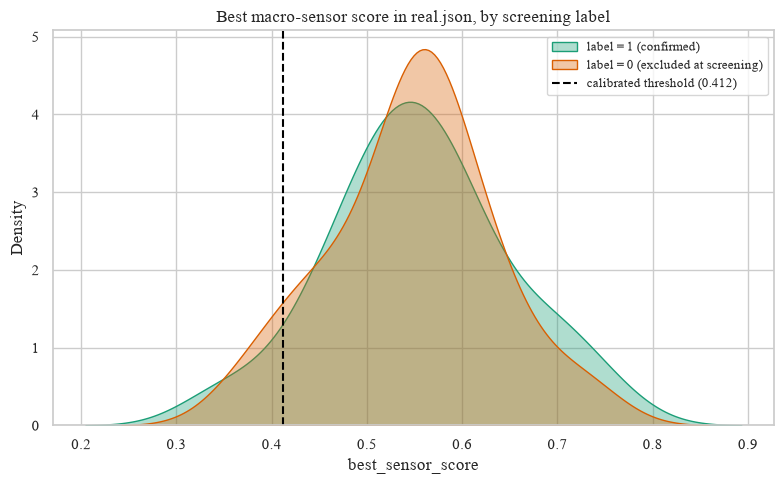

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
for label_value, label_name, color in [(1, "label = 1 (confirmed)", "#1b9e77"),
                                        (0, "label = 0 (excluded at screening)", "#d95f02")]:
    subset = calib_df.loc[calib_df["label"] == label_value, "best_sensor_score"]
    sns.kdeplot(subset, ax=ax, fill=True, alpha=0.35, color=color, label=label_name, clip=(0, 1))
ax.axvline(CALIBRATED_THRESHOLD, color="black", linestyle="--", linewidth=1.5,
           label=f"calibrated threshold ({CALIBRATED_THRESHOLD:.3f})")
ax.set_title("Best macro-sensor score in real.json, by screening label")
ax.set_xlabel("best_sensor_score")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()


## Assign sensor categories

In [10]:
CONFIG_SCORE_THRESHOLD = CALIBRATED_THRESHOLD

def assign_macro_sensor_categories(macro_scores, gated_categories, threshold):
    """Assign gated categories whose scores meet the threshold."""
    gated = set(gated_categories)
    return [
        category for category, score in macro_scores.items()
        if category in gated and score >= threshold
    ]

df_filtered["macro_sensor_types"] = [
    assign_macro_sensor_categories(scores, gated, CONFIG_SCORE_THRESHOLD)
    for scores, gated in zip(
        df_filtered["sensor_macro_scores"], df_filtered["sensor_gated_categories"]
    )
]

category_counts = Counter()
for categories in df_filtered["macro_sensor_types"]:
    category_counts.update(categories)

print(f"Threshold used: {CONFIG_SCORE_THRESHOLD:.4f}\n")
print("Sensor category distribution:")
for category, count in category_counts.most_common():
    print(f"  - {category}: {count} abstracts")

avg_categories = np.mean([len(c) for c in df_filtered["macro_sensor_types"]])
multi_category = sum(1 for c in df_filtered["macro_sensor_types"] if len(c) > 1)
zero_category = sum(1 for c in df_filtered["macro_sensor_types"] if len(c) == 0)
print(f"\nAverage sensor categories per abstract: {avg_categories:.2f}")
print(f"Abstracts with multiple sensor categories: {multi_category} ({multi_category/len(df_filtered)*100:.2f}%)")
print(f"Abstracts with no sensor category: {zero_category} ({zero_category/len(df_filtered)*100:.2f}%)")

gate_empty = sum(1 for g in df_filtered["sensor_gated_categories"] if len(g) == 0)
print(f"  - blocked at the gate (no instrument named): {gate_empty}")
print(f"  - gated but below threshold (semantic rejection): {zero_category - gate_empty}")

print("\nGate-blocked records per category:")
suppressed = Counter()
for gated in df_filtered["sensor_gated_categories"]:
    for category in sensor_technologies:
        if category not in set(gated):
            suppressed[category] += 1
for category, n in suppressed.most_common():
    print(f"  - {category}: gate-blocked in {n}, assigned in {category_counts.get(category, 0)}")


Threshold used: 0.4123

Sensor category distribution:
  - Optical Imaging: 246 abstracts
  - Active Ranging and 3D Scanning: 38 abstracts
  - Positioning and Localization: 23 abstracts
  - Inertial Motion Sensing: 20 abstracts
  - Physiological Sensing: 13 abstracts
  - Atmospheric and Environmental Sensing: 13 abstracts
  - Acoustic Sensing: 1 abstracts

Average sensor categories per abstract: 0.75
Abstracts with multiple sensor categories: 34 (7.17%)
Abstracts with no sensor category: 155 (32.70%)
  - blocked at the gate (no instrument named): 91
  - gated but below threshold (semantic rejection): 64

Gate-blocked records per category:
  - Acoustic Sensing: gate-blocked in 471, assigned in 1
  - Physiological Sensing: gate-blocked in 458, assigned in 13
  - Atmospheric and Environmental Sensing: gate-blocked in 454, assigned in 13
  - Inertial Motion Sensing: gate-blocked in 439, assigned in 20
  - Positioning and Localization: gate-blocked in 426, assigned in 23
  - Active Ranging a

## Category distribution

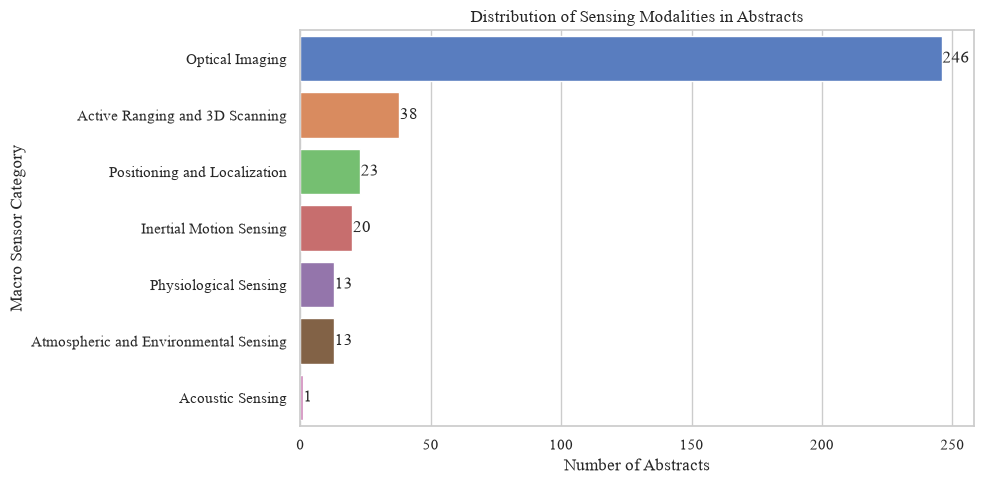

In [11]:
palette = sns.color_palette("muted", n_colors=len(category_counts))
categories_list = [category for category, count in category_counts.most_common()]
counts = [count for category, count in category_counts.most_common()]

plt.figure(figsize=(10, 5))
sns.barplot(x=counts, y=categories_list, hue=categories_list, palette=palette, legend=False)
plt.xlabel("Number of Abstracts")
plt.ylabel("Macro Sensor Category")
plt.title("Distribution of Sensing Modalities in Abstracts")

for i, count in enumerate(counts):
    plt.text(count + 0.2, i, str(count), va="center")

plt.tight_layout()
plt.show()


## Unassigned articles

In [12]:
no_category_mask = df_filtered["macro_sensor_types"].apply(lambda x: len(x) == 0)
no_category_df = df_filtered[no_category_mask]

df_filtered = df_filtered[~no_category_mask].copy()
df_filtered = df_filtered.reset_index(drop=True)
print(f"Filtered DataFrame size: {len(df_filtered)} articles with an assigned sensor category")
print(f"Articles with no sensor category assigned: {len(no_category_df)}")


Filtered DataFrame size: 319 articles with an assigned sensor category
Articles with no sensor category assigned: 155


## Save results

In [ ]:
df_filtered.to_json("../data/06_2_classified_sensor_types.json", orient="records", indent=4)
no_category_df.to_json("../data/06_2_no_assigned_sensor_types.json", orient="records", indent=4)

print(f"Saved:\n  ../data/06_2_classified_sensor_types.json ({len(df_filtered)} records)"
      f"\n  ../data/06_2_no_assigned_sensor_types.json ({len(no_category_df)} records)")


Saved:
  ../data/06_2_classified_sensor_types_v8.json (319 records)
  ../data/06_2_no_assigned_sensor_types_v8.json (155 records)
